# Implementation Fidelity in an Agricultural Futures Portfolio
FINM 37000 · Varshini · Lucie · Jacopo · Alan

In [37]:
# Setup: runs the frozen Section 5 analysis (~15 s) and loads the saved charts.
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/section0/freeze.json").is_file())
sys.path.insert(0, str(ROOT))
from src.validation.schemas import load_project_config
from src.integration.section5 import run_section5
from src.integration.exports import selection_rows, write_outputs
from src.integration.presentation import chart, winner
result = run_section5(ROOT / "data/section0", ROOT / "outputs", load_project_config(ROOT / "config/project.yaml"))
write_outputs(result, ROOT / "outputs", ROOT / "outputs/final")
picks = selection_rows(result, ROOT / "outputs")

## 1. Project idea and benchmark

- **Portfolio:** Corn (ZC), Soybeans (ZS), Wheat (ZW), equal notional
- **Benchmark:** each commodity held at a constant **60 trading sessions** to first notice
- **Question:** which practical implementation rules keep a real portfolio closest to it?
- Implementation fidelity, **not** return forecasting. Metric: daily tracking RMSE in bp (lower is better)
- CME data from Databento · 148 trading days, Mar–Sep 2026

*We are not trying to predict prices or make money. We decide what we want to hold, then measure how closely a real portfolio can actually hold it once contracts expire, positions must be whole numbers and markets have limited trading volume.*

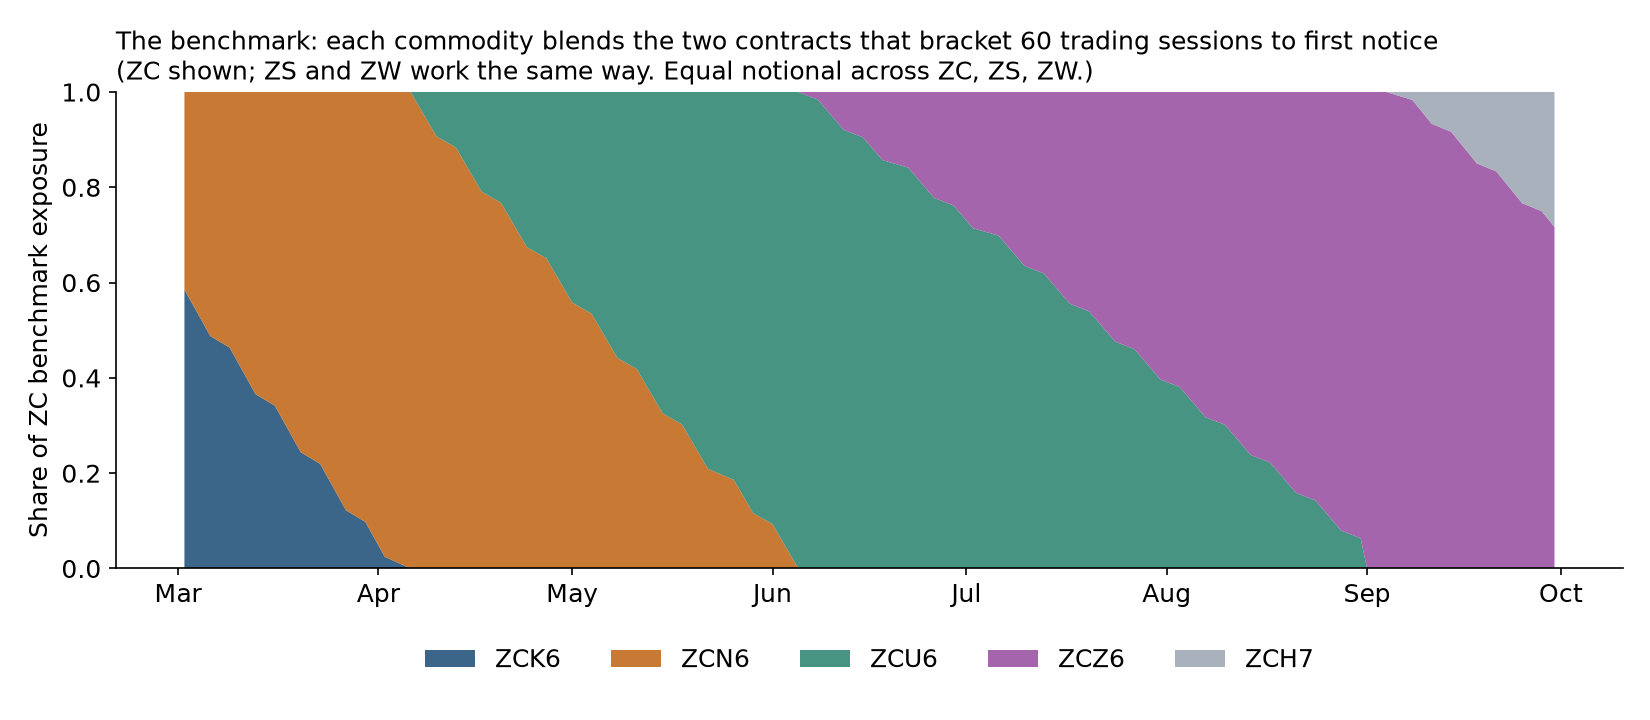

In [38]:
chart(ROOT, "benchmark")

## 2. Contract destination: Varshini
**Question: which contract do we roll into?**

*Futures expire, so before delivery we must swap into a later contract. This asks which later contract to pick: the very next one, or one further out.*

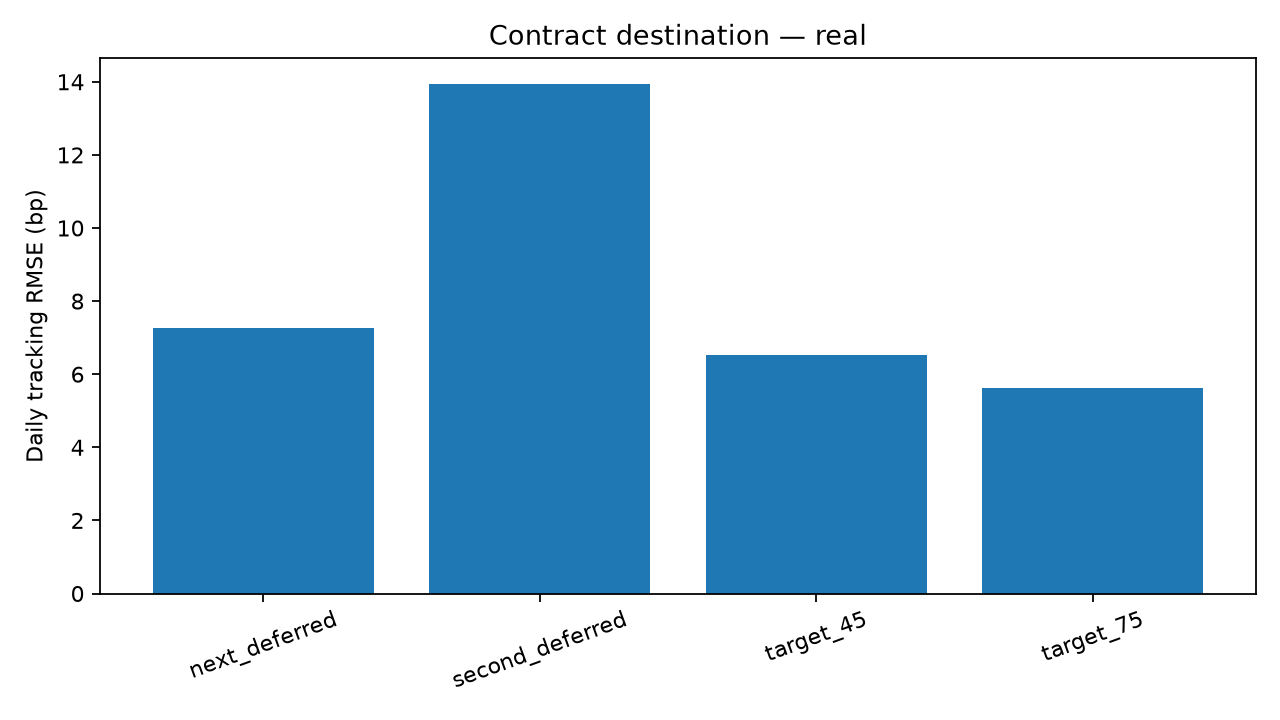

### Winner: 75-session target: 5.623 bp
vs 7.258 bp for the baseline (next deferred), at $10m

In [39]:
chart(ROOT, "destination")
winner(picks, "destination")

**Takeaway:** rolling further out keeps holdings closer to the benchmark's 60-session maturity (about 70 sessions on average, vs 29 for the next contract).

## 3. Roll timing: Lucie
**Question: when do we roll?**

*Given which contract we are swapping into, this asks which day to make the swap: on a fixed date, or when the market's trading activity has moved to the new contract.*

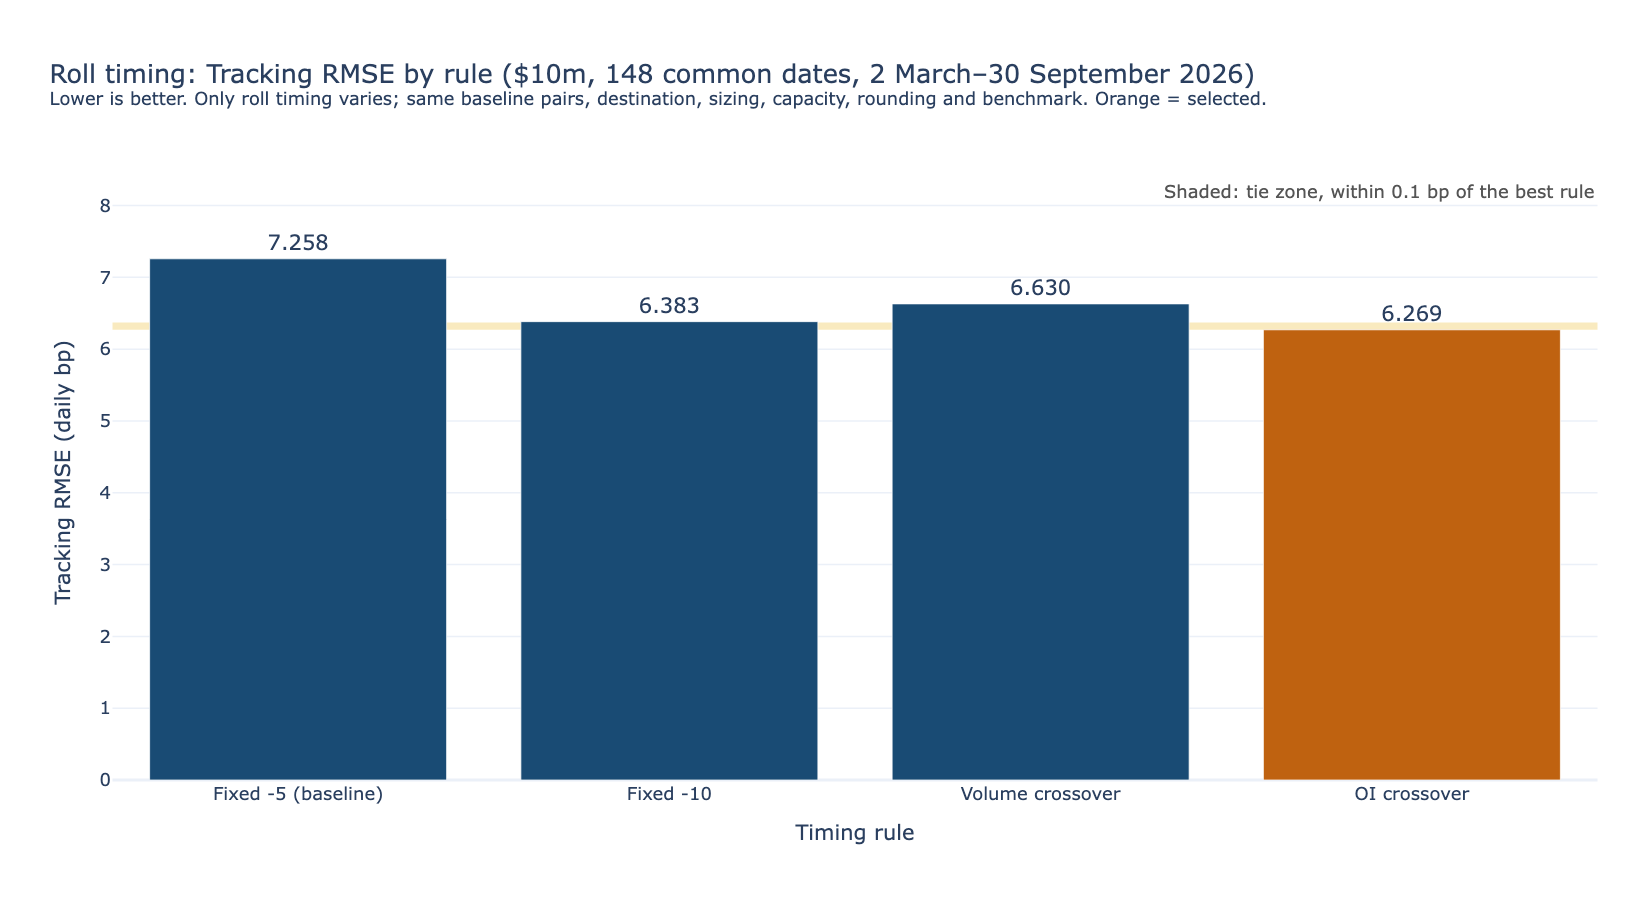

### Winner: OI crossover: 6.269 bp
vs 7.258 bp for the baseline (fixed -5), at $10m

In [40]:
chart(ROOT, "timing")
winner(picks, "timing")

**Takeaway:** rolling earlier tracks better. OI crossover rolls when the next contract's open interest overtakes, about 16 sessions before first notice. For thin **September** contracts the next contract already led, so the rule rolled immediately and largely skipped them.

## 4. Capacity: Jacopo
**Question: what happens when the position is too big for the market's liquidity?**

*A very large portfolio cannot buy unlimited contracts without moving the price, so we cap each position at 2.5% of normal daily trading. This asks what to do with the part that doesn't fit.*

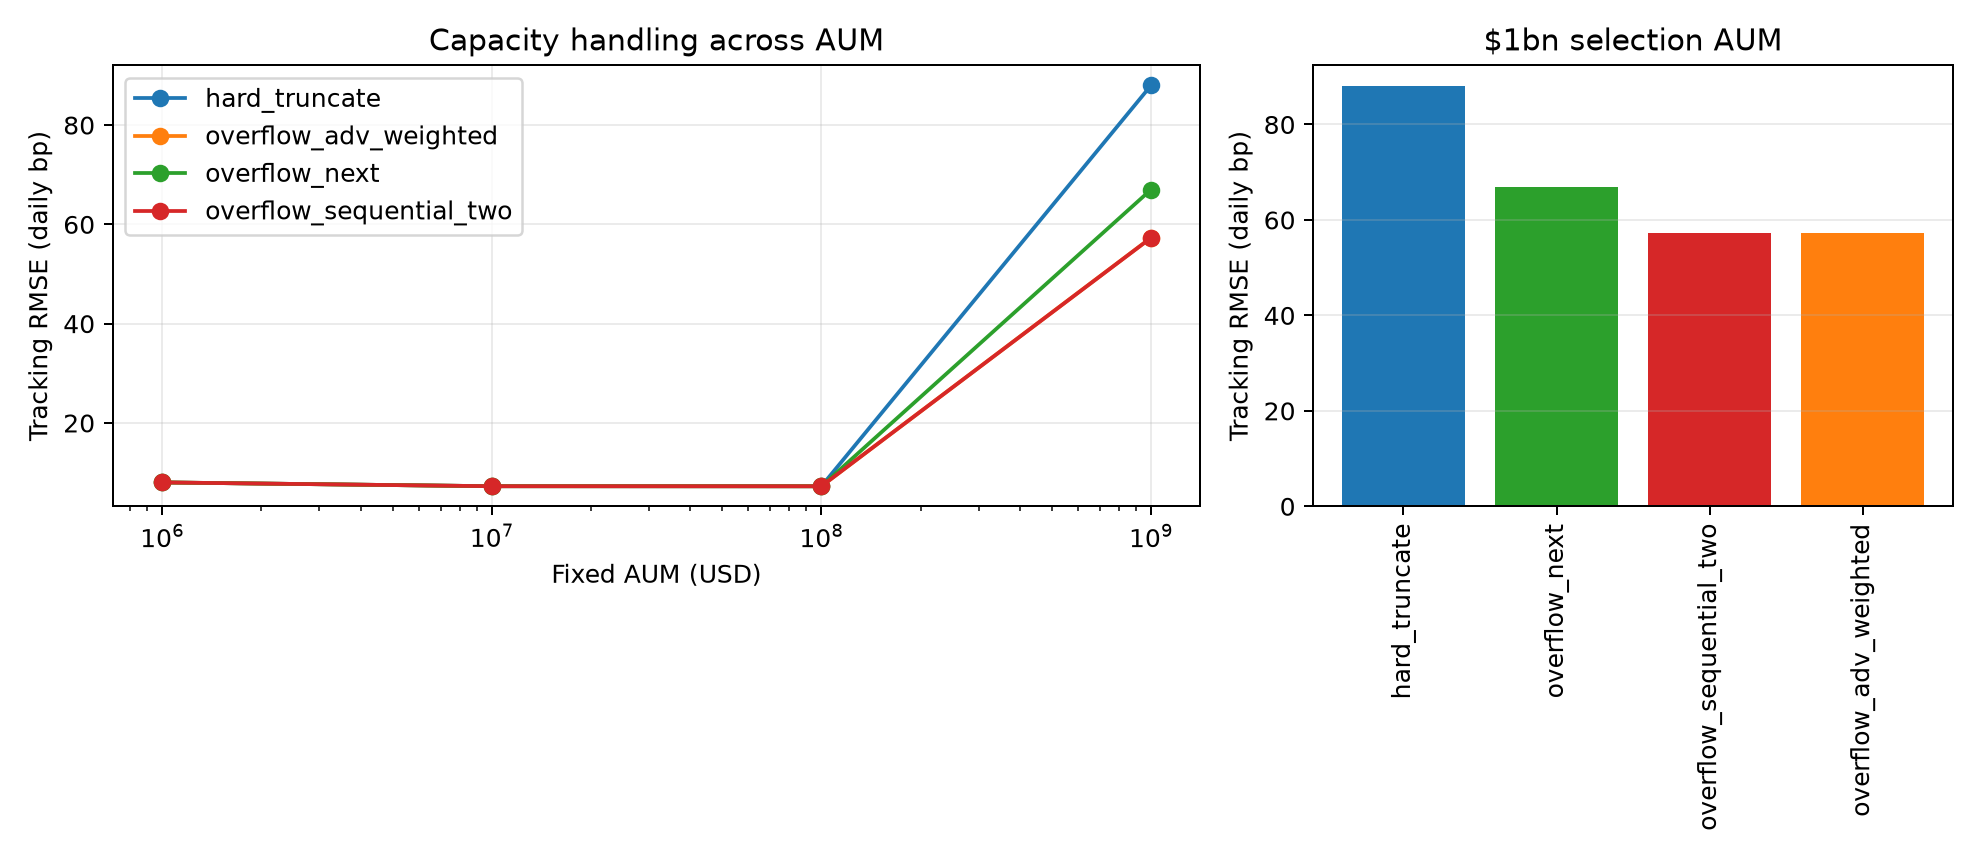

### Winner: Sequential two-deferred overflow: 57.283 bp
vs 87.981 bp for the baseline (hard truncate), at $1bn

In [41]:
chart(ROOT, "capacity")
winner(picks, "capacity")

**Takeaway:** capacity (2.5% of average daily volume) only binds at **$1bn**. Spilling the excess into the next two contracts recovers 44% of the capped exposure (vs 0% when truncating). It tied with ADV-weighted overflow (within 0.1 bp), so the simpler sequential rule was chosen.

## 5. Rounding: Alan
**Question: how do we turn fractional holdings into whole contracts?**

*The ideal position might be 14.6 contracts, but you can only buy whole contracts. This asks whether to round normally, always down, always up, or by a smarter rule.*

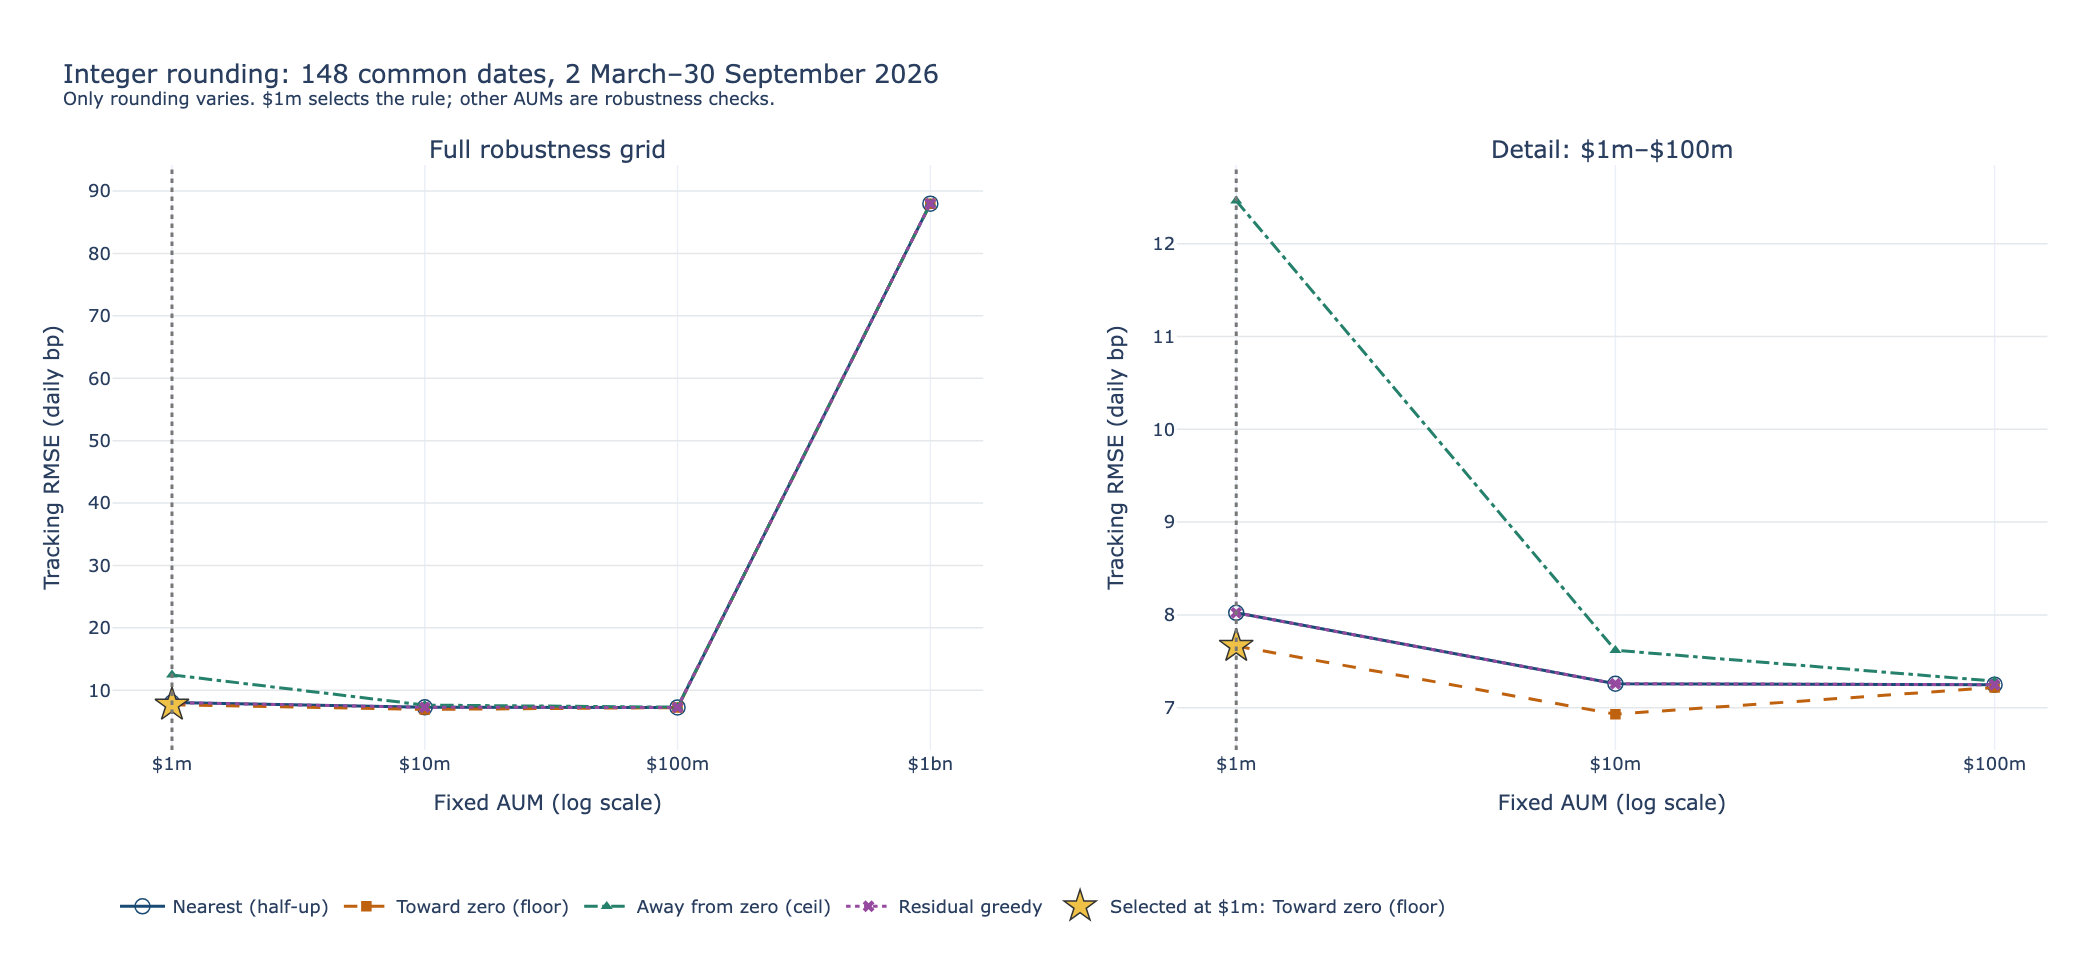

### Winner: Toward zero: 7.664 bp
vs 8.022 bp for the baseline (nearest), at $1m

In [42]:
chart(ROOT, "rounding")
winner(picks, "rounding")

**Takeaway:** rounding matters for small portfolios. The differences shrink by $100m and disappear at $1bn, where the capacity cap binds every position.

## 6. Integrated result: combining the four winners
**75-session destination → OI crossover timing → sequential two-deferred capacity → toward-zero rounding**, combined once with nothing re-optimised. Timing may roll earlier than destination's scheduled roll, never later.

*We took the best rule from each of the four questions and used them all together in one portfolio, to see whether the four improvements add up.*

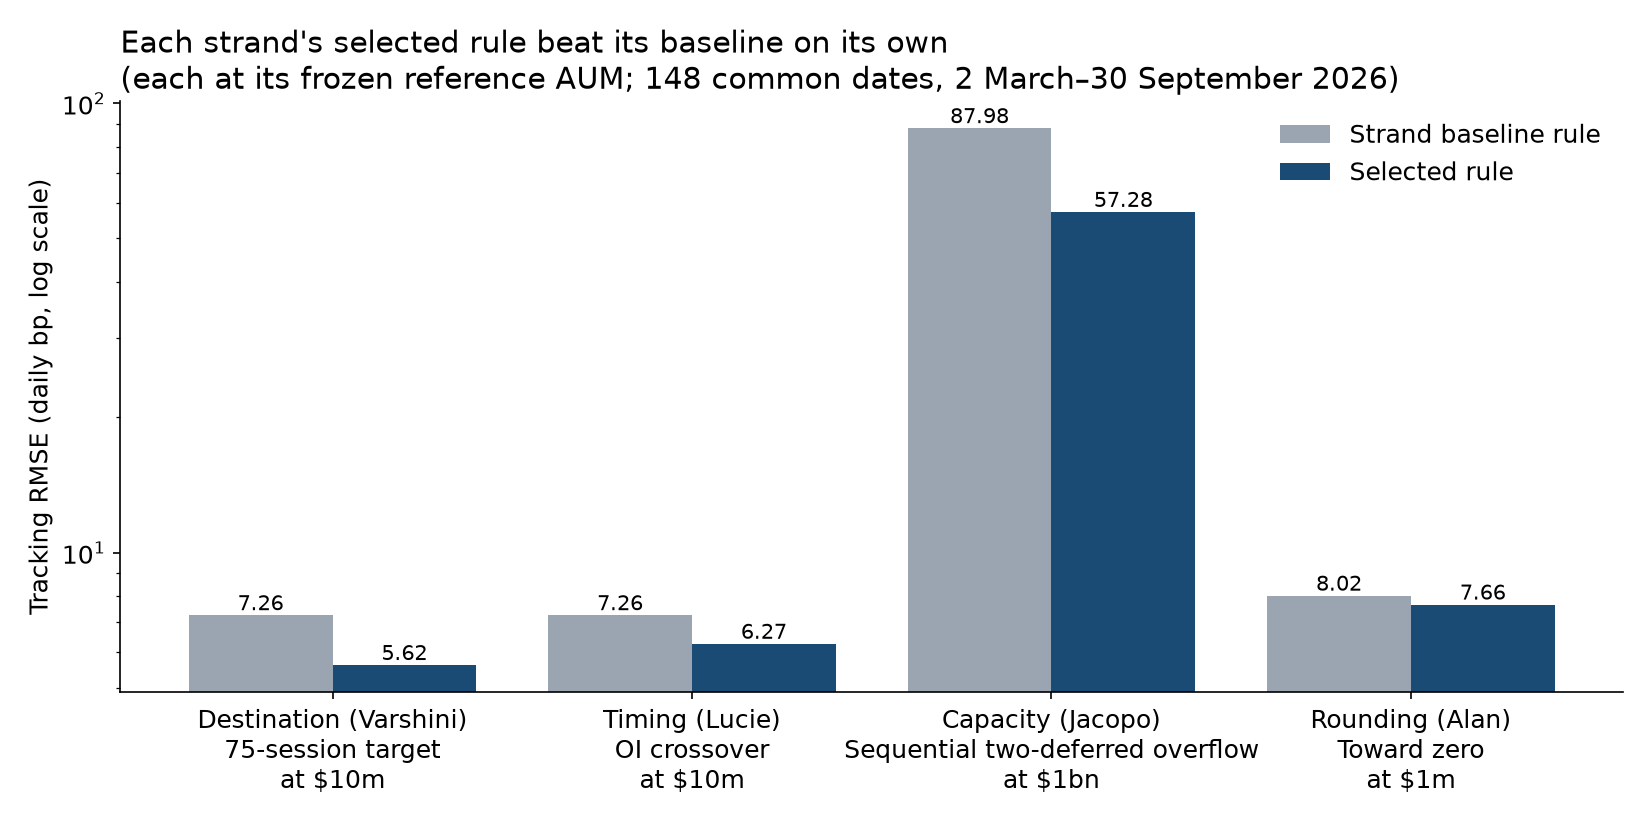

In [43]:
chart(ROOT, "alone")

**Every selected rule improves tracking on its own…**

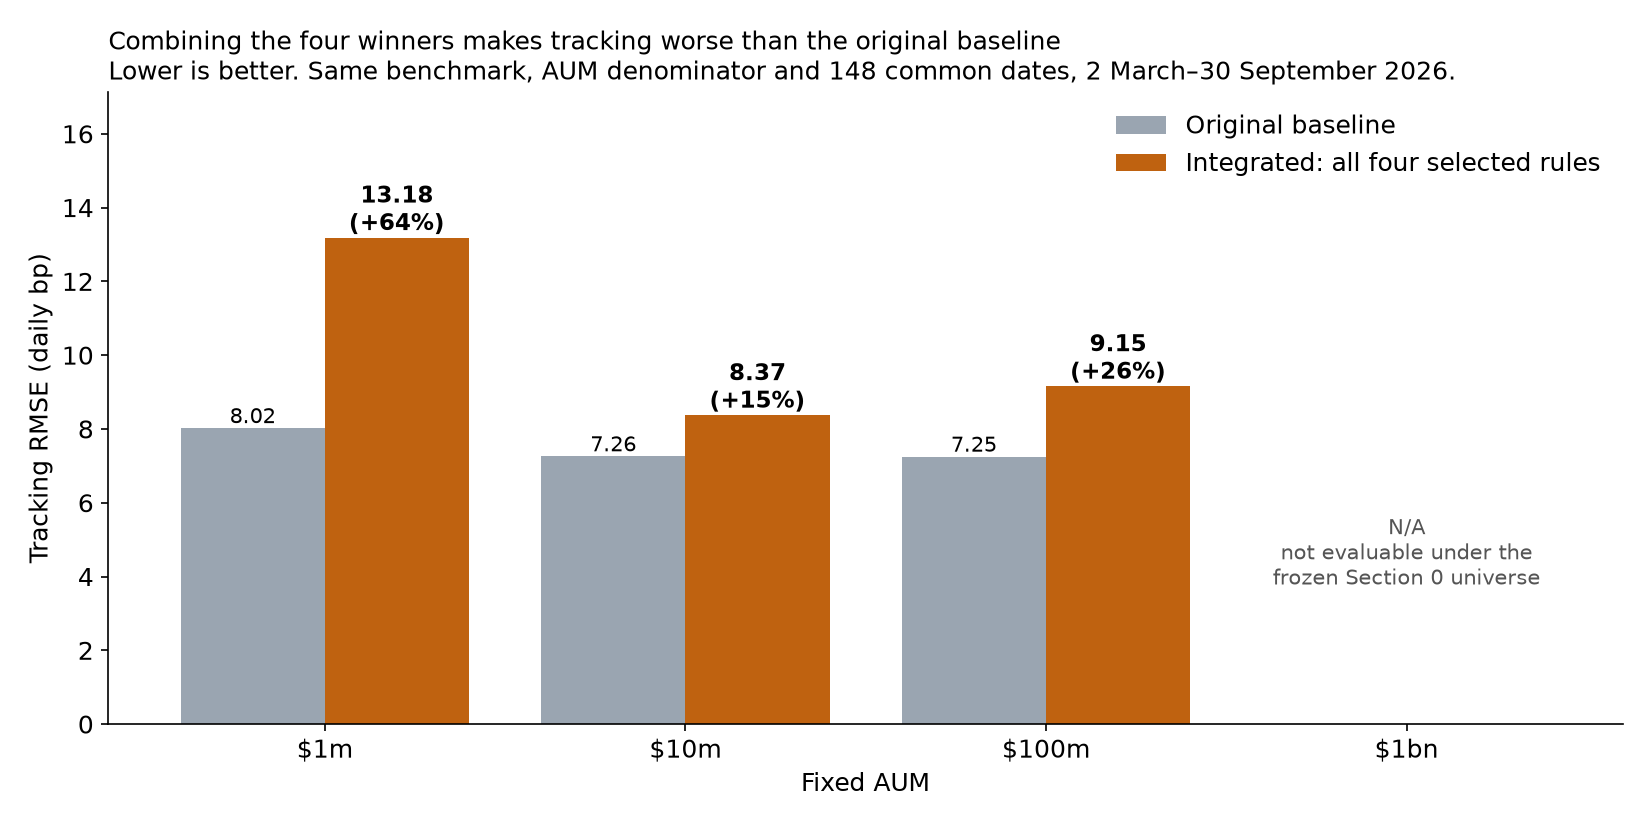

In [44]:
chart(ROOT, "combined")

### …but combined, the four winners track *worse* than the original baseline: about +64%, +15% and +26% at $1m, $10m and $100m

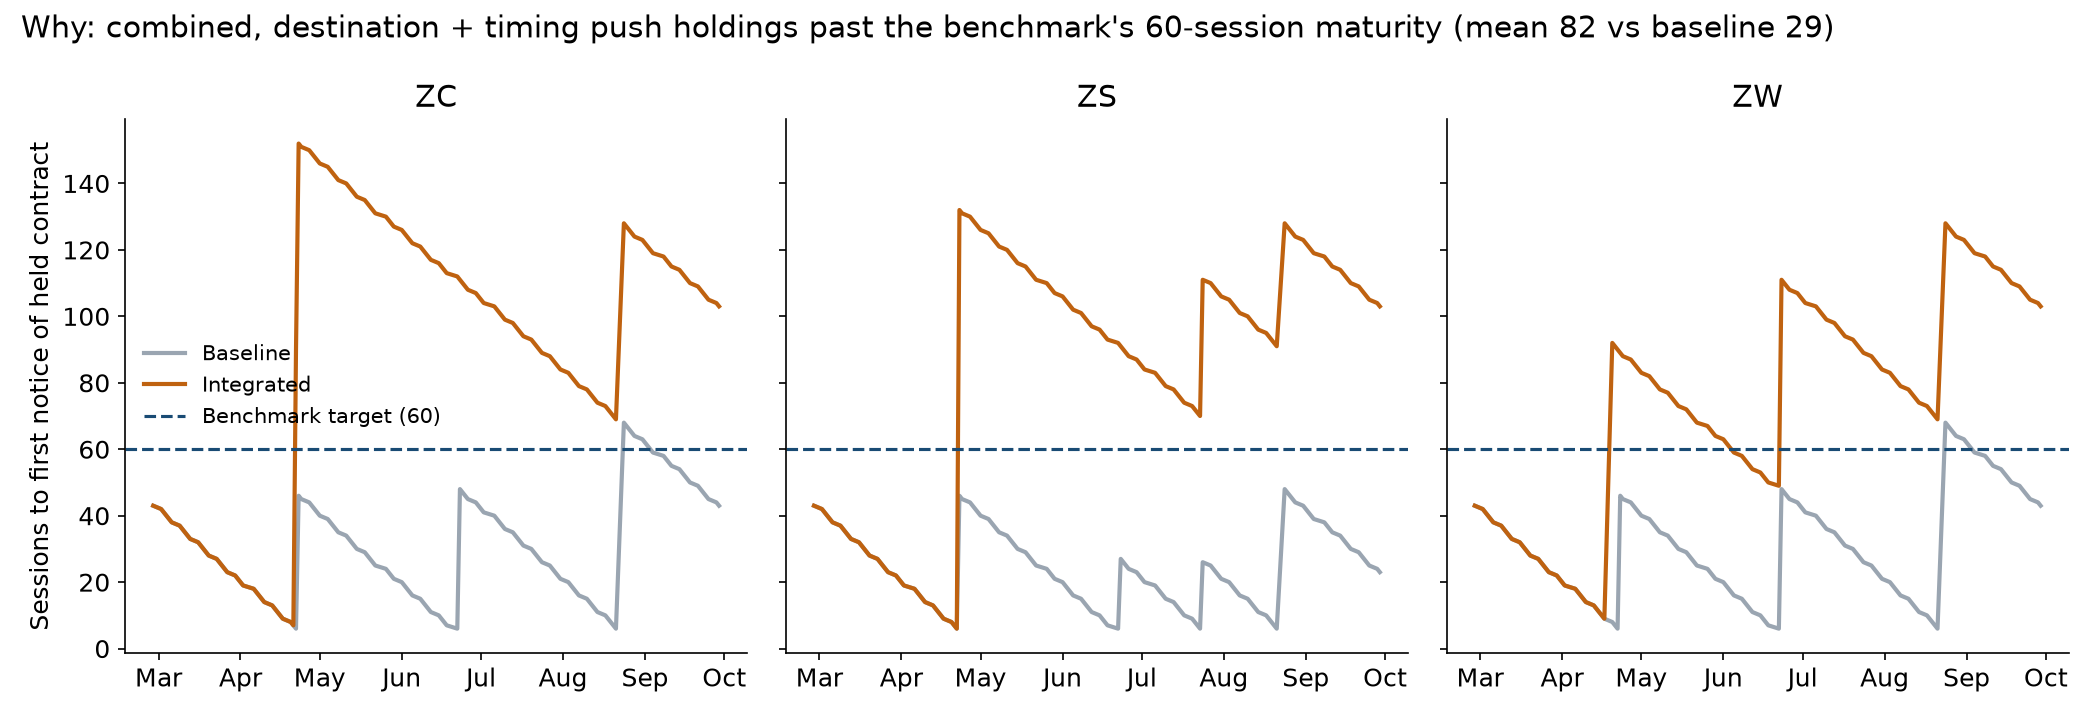

In [45]:
chart(ROOT, "why", width=1050)

**Why:** target_75 and OI crossover reinforce each other, pushing holdings to about **82 sessions** from first notice vs the benchmark's **60**. Each rule run alone inside the Section 5 code reproduces its original result **exactly**, so this is a genuine **interaction between independently selected rules**, not a coding discrepancy.

**Conclusion:** implementation rules that each look best in isolation can conflict when combined. They should be validated together.

<small>$1bn: N/A. The integrated overflow path needs ZSK7, which is outside the frozen Section 0 data universe.</small>